# 08 · Heisenberg (1927)

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JasonDE03/sophon/blob/main/lab/08_heisenberg.ipynb)

Dựng gói sóng, kiểm tra bất định bằng FFT, theo dõi sự giãn tự do, rồi tính kính hiển vi của Heisenberg. Chạy từ trên xuống; không tải dữ liệu.
*Build packets, check uncertainty with an FFT, follow free spreading, then calculate Heisenberg's microscope. Run top to bottom; no data downloads.*

Ở phần gói sóng, Δ là **độ lệch chuẩn** và $p=\hbar k$. Dùng x theo nm và k theo nm⁻¹; các phép tính thời gian và kính hiển vi chuyển sang SI.
*For packets, Δ means **standard deviation** and $p=\hbar k$. Use nm and nm⁻¹ for the Fourier pair, and SI for time evolution and the microscope.*


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import m_e

# Match the web simulation; hbar is rounded to the supplied nine decimals.
HBAR_SI = 1.054571817e-34
H_SI = 6.62607015e-34
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': 0.2})

def spread(values, weights):
    weights = np.asarray(weights, dtype=float)
    weights = weights / weights.sum()
    mean = np.sum(values * weights)
    return np.sqrt(np.sum((values - mean)**2 * weights))

def plane_wave_packet(x, k0, sigma_k, n_k=1001, extent=8):
    k = np.linspace(k0 - extent * sigma_k, k0 + extent * sigma_k, n_k)
    amplitude = np.exp(-(k - k0)**2 / (4 * sigma_k**2))
    psi = np.exp(1j * x[:, None] * k) @ amplitude / amplitude.sum()
    return psi, k, amplitude


## 1. Cộng sóng và kiểm tra FFT / Superposition and the FFT

$\psi(x)=\sum_j a_j e^{ik_jx}$ với $a_j\propto\exp[-(k_j-k_0)^2/(4\sigma_k^2)]$. Vì $|a|^2$ có độ lệch chuẩn $\sigma_k$, Fourier cho $\Delta x=1/(2\sigma_k)$ và $\Delta x\Delta k=1/2$. Cộng sóng trên miền ±8σ để kiểm tra gần giới hạn chính xác; mô phỏng web dùng ±5σ và sai khác nhỏ do cắt đuôi.
*Sum plane waves with a Gaussian amplitude spectrum. Its probability spectrum has standard deviation σk, so the exact Gaussian reaches Δx Δk = 1/2. This notebook sums over ±8σ; the web simulation uses ±5σ and has a small truncation error.*


Direct plane-wave sums (x in nm, k in inverse nm)
   sigma_k      Delta x      Delta k        Product
      0.30     1.666667     0.300000   0.5000000000
      1.00     0.500000     1.000000   0.5000000000


      3.00     0.166667     3.000000   0.5000000000


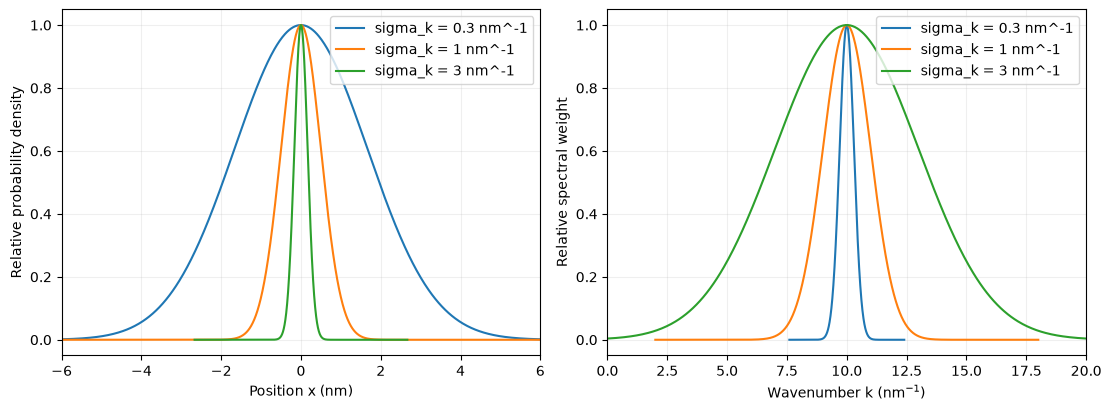

Independent FFT: Delta x Delta k = 0.50000000000000


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
print('Direct plane-wave sums (x in nm, k in inverse nm)')
print(f"{'sigma_k':>10s} {'Delta x':>12s} {'Delta k':>12s} {'Product':>14s}")
for sigma_k in [0.3, 1.0, 3.0]:
    x_sum = np.linspace(-8 / sigma_k, 8 / sigma_k, 3201)
    psi_sum, k_sum, a_sum = plane_wave_packet(x_sum, 10, sigma_k)
    dx = spread(x_sum, abs(psi_sum)**2)
    dk = spread(k_sum, abs(a_sum)**2)
    exact = np.exp(-sigma_k**2 * x_sum**2 + 10j * x_sum)
    assert np.max(abs(psi_sum - exact)) < 5e-8
    assert np.isclose(dx * dk, 0.5, rtol=1e-8)
    print(f'{sigma_k:10.2f} {dx:12.6f} {dk:12.6f} {dx * dk:14.10f}')
    ax[0].plot(x_sum, abs(psi_sum)**2, label=f'sigma_k = {sigma_k:g} nm^-1')
    ax[1].plot(k_sum, abs(a_sum)**2, label=f'sigma_k = {sigma_k:g} nm^-1')
ax[0].set(xlim=(-6, 6), xlabel='Position x (nm)', ylabel='Relative probability density')
ax[1].set(xlim=(0, 20), xlabel='Wavenumber k (nm$^{-1}$)', ylabel='Relative spectral weight')
for panel in ax:
    panel.legend()
plt.show()

# Independent FFT of an analytic position-space Gaussian, with angular k = 2 pi f.
N, spacing = 2**15, 0.02
x = (np.arange(N) - N // 2) * spacing
k = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(N, d=spacing))
sigma_x = 0.5
psi_gauss = np.exp(-x**2 / (4 * sigma_x**2))
A_fft = np.fft.fftshift(np.fft.fft(np.fft.ifftshift(psi_gauss))) * spacing
fft_product = spread(x, abs(psi_gauss)**2) * spread(k, abs(A_fft)**2)
print(f'Independent FFT: Delta x Delta k = {fft_product:.14f}')
assert np.isclose(fft_product, 0.5, rtol=1e-12)


Phổ chữ nhật tạo gói sinc với đuôi xác suất $\sim1/x^2$: phương sai vị trí trên toàn trục **phân kỳ**. Giá trị trên cửa sổ hữu hạn phụ thuộc cửa sổ và lớn dần khi mở rộng. Hai gói Gaussian cách nhau tạo một trạng thái thuần chồng chập; nó không còn là một Gaussian tối thiểu.
*A rectangular spectrum gives a sinc packet with probability tails ∝ 1/x²: its full-line position variance **diverges**. Finite-window estimates grow as the window expands. A coherent superposition of two separated Gaussians is also no longer a single minimum-uncertainty Gaussian.*


Rectangular spectrum: finite-window estimates, not a finite full-line SD
Window +/-10 nm: Delta x Delta k = 1.370227
Window +/-20 nm: Delta x Delta k = 1.924681
Window +/-40 nm: Delta x Delta k = 2.719750
Window +/-80 nm: Delta x Delta k = 3.865660
Two-Gaussian coherent superposition: Delta x Delta k = 2.055690


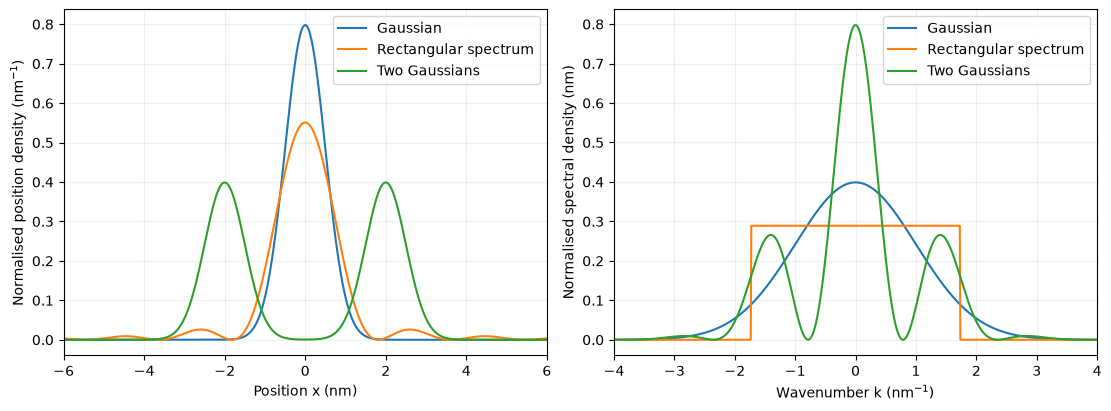

In [3]:
def inverse_spectrum(amplitude):
    return np.fft.fftshift(np.fft.ifft(np.fft.ifftshift(amplitude)))

# Choose the rectangle's half-width so its continuous spectral SD is 1 nm^-1.
A_rect = (abs(k) <= np.sqrt(3)).astype(float)
psi_rect = inverse_spectrum(A_rect)
dk_rect = spread(k, A_rect**2)
half_windows = [10, 20, 40, 80]
rect_products = []
print('Rectangular spectrum: finite-window estimates, not a finite full-line SD')
for half_window in half_windows:
    inside = abs(x) <= half_window
    dx_rect = spread(x[inside], abs(psi_rect[inside])**2)
    rect_products.append(dx_rect * dk_rect)
    print(f'Window +/-{half_window:2d} nm: Delta x Delta k = {rect_products[-1]:.6f}')
assert all(value > 0.5 for value in rect_products)
assert np.all(np.diff(rect_products) > 0)

# The two terms have the same phase and centres at +/-2 nm (separation 4 nm).
separation = 4.0
psi_double = (np.exp(-(x - separation / 2)**2 / (4 * sigma_x**2))
              + np.exp(-(x + separation / 2)**2 / (4 * sigma_x**2)))
A_double = np.fft.fftshift(np.fft.fft(np.fft.ifftshift(psi_double))) * spacing
double_product = spread(x, abs(psi_double)**2) * spread(k, abs(A_double)**2)
assert double_product > 0.5
print(f'Two-Gaussian coherent superposition: Delta x Delta k = {double_product:.6f}')

fig, ax = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
for label, wave, spectrum in [('Gaussian', psi_gauss, A_fft),
                               ('Rectangular spectrum', psi_rect, A_rect),
                               ('Two Gaussians', psi_double, A_double)]:
    density = abs(wave)**2
    spectral_density = abs(spectrum)**2
    ax[0].plot(x, density / (density.sum() * spacing), label=label)
    ax[1].plot(k, spectral_density / (spectral_density.sum() * (k[1] - k[0])), label=label)
ax[0].set(xlim=(-6, 6), xlabel='Position x (nm)', ylabel='Normalised position density (nm$^{-1}$)')
ax[1].set(xlim=(-4, 4), xlabel='Wavenumber k (nm$^{-1}$)', ylabel='Normalised spectral density (nm)')
for panel in ax:
    panel.legend()
plt.show()


## 2. Gói sóng tự giãn / Free spreading

Với Gaussian tự do ban đầu không có tương quan x–p,
$$\sigma(t)=\sigma_0\sqrt{1+\left(\frac{\hbar t}{2m\sigma_0^2}\right)^2}.$$
Thời gian đặc trưng $\tau=2m\sigma_0^2/\hbar$ làm độ rộng tăng $\sqrt2$ lần. Hạt bụi **1 µg = 10⁻⁹ kg**, không phải 1 µm; so sánh ở cùng độ rộng tâm khối 0,1 nm.
*For an initially uncorrelated free Gaussian, τ = 2mσ₀²/ℏ is the time to grow by √2. The dust mass is **1 µg = 10⁻⁹ kg**; compare its centre-of-mass packet at the same initial width of 0.1 nm.*

Electron tự do ở độ rộng nguyên tử giãn rất nhanh; khối lượng lớn của bụi làm giãn chậm. Công thức này cũng mô tả tâm khối của nguyên tử **tự do**, không áp dụng trực tiếp cho electron liên kết trong nguyên tử hay nguyên tử bị giữ trong bẫy. Kích thước nội tại của nguyên tử không phải độ rộng gói tâm khối.
*A free electron localised to atomic dimensions spreads quickly; a dust grain's large mass suppresses spreading. This also applies to a **free** atom's centre of mass, not directly to a bound electron or a trapped atom. An atom's internal size is distinct from its centre-of-mass packet width.*


Packet                                tau (s)     sigma at 1 ps (nm)      sigma at 1 s (nm)
Electron, 0.1 nm                 1.727599e-16                578.838            5.78838e+14
Electron, 1 nm                   1.727599e-14                57.8925            5.78838e+13
1 microgram dust, 0.1 nm         1.896504e+05                    0.1                    0.1


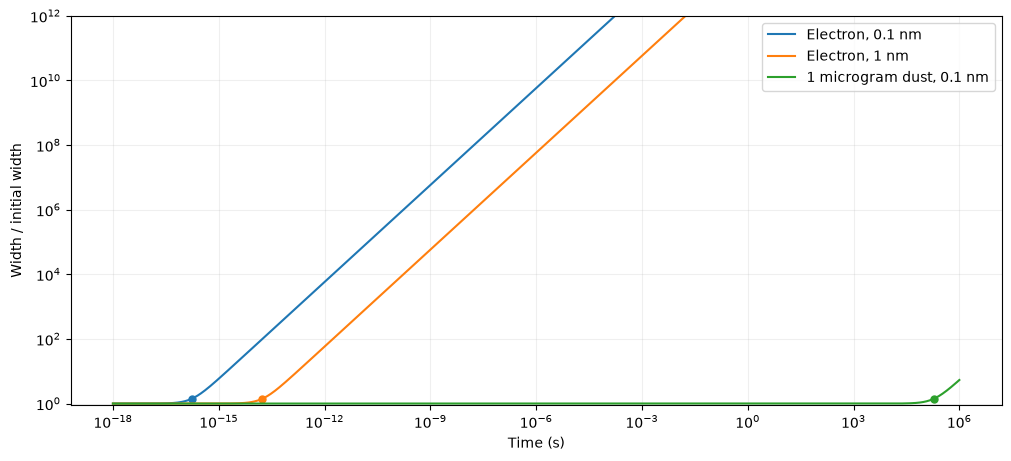

In [4]:
def width(t, mass, sigma0):
    tau = 2 * mass * sigma0**2 / HBAR_SI
    return sigma0 * np.hypot(1, t / tau)

cases = [('Electron, 0.1 nm', m_e, 0.1e-9),
         ('Electron, 1 nm', m_e, 1e-9),
         ('1 microgram dust, 0.1 nm', 1e-9, 0.1e-9)]
print(f"{'Packet':30s} {'tau (s)':>14s} {'sigma at 1 ps (nm)':>22s} {'sigma at 1 s (nm)':>22s}")
fig, ax = plt.subplots(figsize=(10, 4.5), layout='constrained')
times = np.geomspace(1e-18, 1e6, 800)
for label, mass, sigma0 in cases:
    tau = 2 * mass * sigma0**2 / HBAR_SI
    assert np.isclose(width(tau, mass, sigma0) / sigma0, np.sqrt(2), rtol=1e-12)
    print(f'{label:30s} {tau:14.6e} {width(1e-12, mass, sigma0) * 1e9:22.6g} {width(1, mass, sigma0) * 1e9:22.6g}')
    ax.loglog(times, width(times, mass, sigma0) / sigma0, label=label)
    ax.scatter([tau], [np.sqrt(2)], s=25)
ax.set(xlabel='Time (s)', ylabel='Width / initial width', ylim=(0.9, 1e12))
ax.legend()
plt.show()


## 3. Kính hiển vi tia gamma / The gamma-ray microscope

Với nửa góc mở ε = 30°, dùng $\Delta x=\lambda/(2\sin\varepsilon)$ và khoảng cú hích $\Delta p=2(h/\lambda)\sin\varepsilon$. Tích bằng h theo đúng quy ước của mô hình này. Δp là **toàn khoảng** của cú hích ngang, không phải độ lệch chuẩn; nếu lấy phân bố đều thì độ lệch chuẩn là Δp/√12. Mô hình ảnh trong web lấy σ = Δx/2 để vẽ đám điểm.
*At half-angle ε = 30°, the model's resolution and full kick range multiply to h. Δp is the **full range**, not an SD: a uniform kick has SD Δp/√12. The web's illustrative position cloud has SD Δx/2.*

Đây là thí nghiệm tưởng tượng, không phải thiết kế kính hiển vi gamma thực tế; ở bước sóng rất ngắn, các hiệu ứng tương đối tính và tương tác khác cũng quan trọng.
*This is a thought experiment, not a practical gamma microscope design; at very short wavelengths, relativistic effects and other interactions also matter.*


In [5]:
def microscope(lambda_nm, epsilon):
    dx_m = lambda_nm * 1e-9 / (2 * np.sin(epsilon))
    dp_si = 2 * H_SI / (lambda_nm * 1e-9) * np.sin(epsilon)
    return dx_m, dp_si, dx_m * dp_si

epsilon = np.deg2rad(30)
print(f"{'lambda (nm)':>14s} {'Delta x (nm)':>16s} {'Delta p (kg m/s)':>20s} {'Product (J s)':>18s} {'Product/h':>12s}")
for lambda_nm in [500, 100, 10, 1, 0.1, 0.01, 0.001]:
    dx_m, dp_si, product = microscope(lambda_nm, epsilon)
    print(f'{lambda_nm:14g} {dx_m * 1e9:16.6g} {dp_si:20.9e} {product:18.9e} {product / H_SI:12.9f}')
    assert np.isclose(product / H_SI, 1, rtol=1e-12)
for epsilon_deg in [5, 30, 60]:
    a = microscope(500, np.deg2rad(epsilon_deg))
    b = microscope(250, np.deg2rad(epsilon_deg))
    assert np.isclose(b[0] / a[0], 0.5, rtol=1e-12)
    assert np.isclose(b[1] / a[1], 2, rtol=1e-12)


   lambda (nm)     Delta x (nm)     Delta p (kg m/s)      Product (J s)    Product/h
           500              500      1.325214030e-27    6.626070150e-34  1.000000000
           100              100      6.626070150e-27    6.626070150e-34  1.000000000
            10               10      6.626070150e-26    6.626070150e-34  1.000000000
             1                1      6.626070150e-25    6.626070150e-34  1.000000000
           0.1              0.1      6.626070150e-24    6.626070150e-34  1.000000000
          0.01             0.01      6.626070150e-23    6.626070150e-34  1.000000000
         0.001            0.001      6.626070150e-22    6.626070150e-34  1.000000000


## 4. Kennard và Heisenberg / Kennard and Heisenberg

Heisenberg (1927) dùng lập luận về phép đo và ước lượng cỡ $\Delta x\Delta p\approx h$; hệ số phụ thuộc cách định nghĩa độ phân giải và nhiễu động. Kennard (1927) chứng minh bất đẳng thức chính xác cho độ lệch chuẩn của vị trí và động lượng trong **cùng một trạng thái**:
$$\sigma_x\sigma_p\geq\frac{\hbar}{2}=\frac{h}{4\pi}.$$
*Heisenberg's 1927 measurement argument estimates an order of magnitude, with convention-dependent factors. Kennard's 1927 exact inequality concerns position and momentum **standard deviations in the same state**.*

Hai con số chuẩn khác nhau hệ số $h/(\hbar/2)=4\pi\approx12{,}566$. Không thể coi đó là hai cận chính xác cho cùng một tích: ở kính hiển vi, ta đang dùng độ phân giải và toàn khoảng cú hích, còn ở Kennard là hai độ lệch chuẩn. Với một Gaussian có thêm pha bậc hai (tương quan x–p), tích hai độ lệch chuẩn có thể lớn hơn ℏ/2; Gaussian thực không có tương quan ở phần 1 đạt dấu bằng.
*The reference scales differ by 4π ≈ 12.566, but are not competing exact bounds for the same definitions. A Gaussian with a quadratic phase can have a larger SD product; the uncorrelated real Gaussian in section 1 attains equality.*

Nguồn gốc / Original papers: W. Heisenberg, *Über den anschaulichen Inhalt der quantentheoretischen Kinematik und Mechanik*, Z. Phys. **43**, 172–198 (1927), [doi:10.1007/BF01397280](https://doi.org/10.1007/BF01397280); E. H. Kennard, *Zur Quantenmechanik einfacher Bewegungstypen*, Z. Phys. **44**, 326–352 (1927), [doi:10.1007/BF01391200](https://doi.org/10.1007/BF01391200).


In [6]:
ratio = H_SI / (HBAR_SI / 2)
print(f'Heisenberg model scale h      = {H_SI:.10e} J s')
print(f'Kennard lower bound hbar / 2  = {HBAR_SI / 2:.10e} J s')
print(f'Ratio h / (hbar / 2)          = {ratio:.10f}')
print(f'4 pi                         = {4 * np.pi:.10f}')
# The tiny discrepancy comes from the rounded HBAR_SI constant.
assert np.isclose(ratio, 4 * np.pi, rtol=1e-9)
print('All Gaussian, FFT, spreading and microscope checks passed.')


Heisenberg model scale h      = 6.6260701500e-34 J s
Kennard lower bound hbar / 2  = 5.2728590850e-35 J s
Ratio h / (hbar / 2)          = 12.5663706221
4 pi                         = 12.5663706144
All Gaussian, FFT, spreading and microscope checks passed.
